In [2]:
# Flight Delay Analysis & Prediction
# DMW Assignment

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("flights_with_weather_2024.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 500000
Number of columns: 33


In [4]:
df.head()

,AIRLINE,AIRLINE_NAME,ORIGIN_AIRPORT,ORIGIN_CITY,DESTINATION_AIRPORT,DESTINATION_CITY,MONTH,DAY,DAY_OF_WEEK,SCHEDULED_DEPARTURE,...,WEATHER_DATETIME,temperature_2m,relative_humidity_2m,precipitation,rain,cloud_cover,wind_speed_10m,wind_direction_10m,pressure_msl,weather_code
0,QP,Akasa Air,PAT,Patna,MAA,Chennai,6,22,6,920,...,22-06-2024 09:00,33.0,63,0.0,0.0,32,13.3,90,1000.9,1
1,6E,IndiGo,CCU,Kolkata,MAA,Chennai,4,21,7,1304,...,21-04-2024 13:00,40.9,27,0.0,0.0,60,10.2,222,1001.6,2
2,I5,AIX Connect,LKO,Lucknow,PAT,Patna,4,18,4,906,...,18-04-2024 09:00,33.8,19,0.0,0.0,0,21.0,292,1007.3,0
3,AI,Air India,DEL,Delhi,BLR,Bengaluru,5,6,1,959,...,06-05-2024 09:00,35.0,24,0.0,0.0,0,7.4,293,1005.2,0
4,6E,IndiGo,AMD,Ahmedabad,CCU,Kolkata,10,9,3,745,...,09-10-2024 07:00,25.2,70,0.0,0.0,11,11.0,58,1011.1,0


In [5]:
print("Columns in the dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Columns in the dataset:

1. AIRLINE
2. AIRLINE_NAME
3. ORIGIN_AIRPORT
4. ORIGIN_CITY
5. DESTINATION_AIRPORT
6. DESTINATION_CITY
7. MONTH
8. DAY
9. DAY_OF_WEEK
10. SCHEDULED_DEPARTURE
11. DEPARTURE_DELAY
12. ARRIVAL_DELAY
13. DISTANCE
14. WEATHER_DELAY
15. AIRLINE_DELAY
16. LATE_AIRCRAFT_DELAY
17. ATC_DELAY
18. TECHNICAL_DELAY
19. CANCELLED
20. DIVERTED
21. YEAR
22. FLIGHT_DATE
23. FLIGHT_DATETIME
24. WEATHER_DATETIME
25. temperature_2m
26. relative_humidity_2m
27. precipitation
28. rain
29. cloud_cover
30. wind_speed_10m
31. wind_direction_10m
32. pressure_msl
33. weather_code


In [6]:
print("Dataset information:\n")
df.info()

print("\nMissing values in each column:\n")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Dataset information:

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 33 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   AIRLINE               500000 non-null  str    
 1   AIRLINE_NAME          500000 non-null  str    
 2   ORIGIN_AIRPORT        500000 non-null  str    
 3   ORIGIN_CITY           500000 non-null  str    
 4   DESTINATION_AIRPORT   500000 non-null  str    
 5   DESTINATION_CITY      500000 non-null  str    
 6   MONTH                 500000 non-null  int64  
 7   DAY                   500000 non-null  int64  
 8   DAY_OF_WEEK           500000 non-null  int64  
 9   SCHEDULED_DEPARTURE   500000 non-null  int64  
 10  DEPARTURE_DELAY       500000 non-null  float64
 11  ARRIVAL_DELAY         500000 non-null  float64
 12  DISTANCE              500000 non-null  int64  
 13  WEATHER_DELAY         500000 non-null  float64
 14  AIRLINE_DELAY         500000 non-null  fl

In [7]:
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

1. AIRLINE
2. AIRLINE_NAME
3. ORIGIN_AIRPORT
4. ORIGIN_CITY
5. DESTINATION_AIRPORT
6. DESTINATION_CITY
7. MONTH
8. DAY
9. DAY_OF_WEEK
10. SCHEDULED_DEPARTURE
11. DEPARTURE_DELAY
12. ARRIVAL_DELAY
13. DISTANCE
14. WEATHER_DELAY
15. AIRLINE_DELAY
16. LATE_AIRCRAFT_DELAY
17. ATC_DELAY
18. TECHNICAL_DELAY
19. CANCELLED
20. DIVERTED
21. YEAR
22. FLIGHT_DATE
23. FLIGHT_DATETIME
24. WEATHER_DATETIME
25. temperature_2m
26. relative_humidity_2m
27. precipitation
28. rain
29. cloud_cover
30. wind_speed_10m
31. wind_direction_10m
32. pressure_msl
33. weather_code


In [8]:
print("Departure delay summary:")
print(df["DEPARTURE_DELAY"].describe())

print("\nNegative delays (early departures):",
      (df["DEPARTURE_DELAY"] < 0).sum())

print("Zero-delay flights:",
      (df["DEPARTURE_DELAY"] == 0).sum())

print("Positive delays:",
      (df["DEPARTURE_DELAY"] > 0).sum())

print("\nCancelled flights:")
print(df["CANCELLED"].value_counts())

print("\nDiverted flights:")
print(df["DIVERTED"].value_counts())

Departure delay summary:
count    500000.000000
mean         23.994021
std          20.289039
min         -20.000000
25%           9.901291
50%          23.487233
75%          37.471537
max         125.564460
Name: DEPARTURE_DELAY, dtype: float64

Negative delays (early departures): 59733
Zero-delay flights: 0
Positive delays: 440267

Cancelled flights:
CANCELLED
0    494020
1      5980
Name: count, dtype: int64

Diverted flights:
DIVERTED
0    499028
1       972
Name: count, dtype: int64


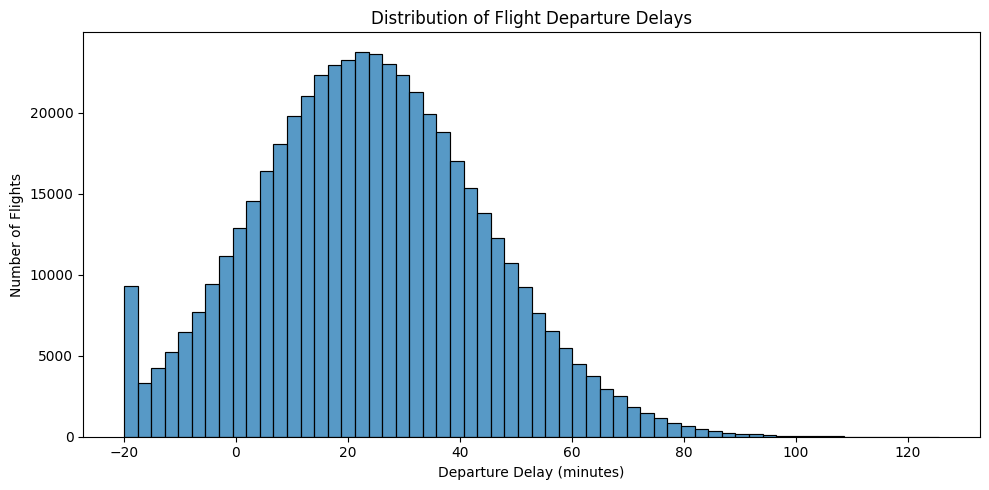

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="DEPARTURE_DELAY", bins=60)

plt.title("Distribution of Flight Departure Delays")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

In [10]:
# Average departure delay for each airline
airline_delay = (
    df.groupby("AIRLINE_NAME")["DEPARTURE_DELAY"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

airline_delay.columns = [
    "Average Delay (min)",
    "Median Delay (min)",
    "Number of Records"
]

display(airline_delay.round(2))

,Average Delay (min),Median Delay (min),Number of Records
AIRLINE_NAME,,,
SpiceJet,32.59,31.91,18420
Alliance Air,30.87,30.50,15929
Akasa Air,26.64,26.10,24175
Air India Express,25.83,25.37,32538
Air India,24.92,24.48,73838
IndiGo,22.63,22.12,309876
AIX Connect,22.55,21.98,25224


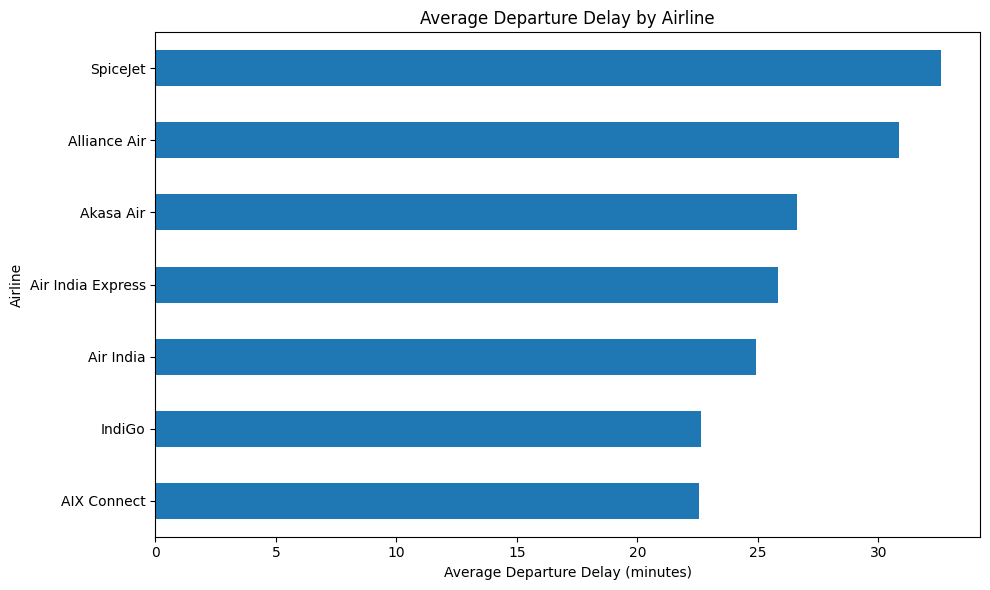

In [11]:
plt.figure(figsize=(10, 6))

airline_delay["Average Delay (min)"].sort_values().plot(
    kind="barh"
)

plt.title("Average Departure Delay by Airline")
plt.xlabel("Average Departure Delay (minutes)")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

In [12]:
weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "rain",
    "cloud_cover",
    "wind_speed_10m",
    "wind_direction_10m",
    "pressure_msl"
]

print("Weather feature summary:")
display(df[weather_columns].describe().round(2))

Weather feature summary:


,temperature_2m,relative_humidity_2m,precipitation,rain,cloud_cover,wind_speed_10m,wind_direction_10m,pressure_msl
count,500000.00,500000.00,500000.00,500000.00,500000.00,500000.00,500000.00,500000.00
mean,27.04,64.72,0.21,0.21,51.83,10.10,197.01,1008.85
std,6.05,23.10,0.96,0.96,43.55,5.67,100.28,5.85
min,4.10,5.00,0.00,0.00,0.00,0.00,0.00,978.80
25%,24.10,48.00,0.00,0.00,2.00,5.90,106.00,1004.90
50%,27.30,69.00,0.00,0.00,52.00,9.00,217.00,1009.30
75%,30.70,84.00,0.00,0.00,100.00,13.40,282.00,1013.10
max,46.90,100.00,43.20,43.20,100.00,44.30,360.00,1024.70


In [13]:
weather_corr = (
    df[weather_columns + ["DEPARTURE_DELAY"]]
    .corr(numeric_only=True)["DEPARTURE_DELAY"]
    .drop("DEPARTURE_DELAY")
    .sort_values()
)

print("Correlation with departure delay:")
display(weather_corr.to_frame("Correlation").round(3))

Correlation with departure delay:


,Correlation
temperature_2m,-0.132
pressure_msl,-0.031
wind_speed_10m,0.003
precipitation,0.015
rain,0.015
cloud_cover,0.043
wind_direction_10m,0.043
relative_humidity_2m,0.140


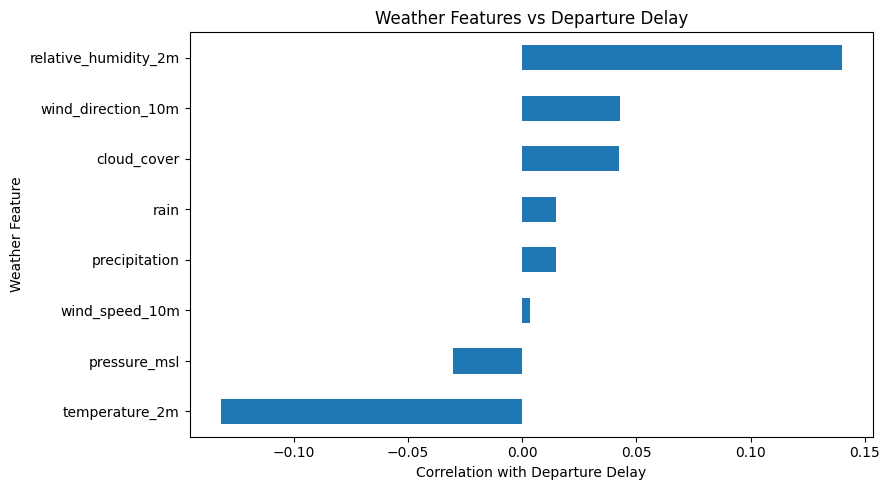

In [14]:
plt.figure(figsize=(9, 5))

weather_corr.plot(kind="barh")

plt.title("Weather Features vs Departure Delay")
plt.xlabel("Correlation with Departure Delay")
plt.ylabel("Weather Feature")
plt.tight_layout()
plt.show()

In [15]:
print("Weather correlations with departure delay:")
display(
    weather_corr.abs()
    .sort_values(ascending=False)
    .to_frame("Absolute Correlation")
    .round(3)
)

Weather correlations with departure delay:


,Absolute Correlation
relative_humidity_2m,0.140
temperature_2m,0.132
wind_direction_10m,0.043
cloud_cover,0.043
pressure_msl,0.031
precipitation,0.015
rain,0.015
wind_speed_10m,0.003


In [16]:
print("Available columns:")
print(df.columns.tolist())

print("\nFlight status counts:")
print("Cancelled:")
print(df["CANCELLED"].value_counts())

print("\nDiverted:")
print(df["DIVERTED"].value_counts())

print("\nDate-related columns:")
print([
    col for col in df.columns
    if "DATE" in col.upper() or "TIME" in col.upper()
])

Available columns:
['AIRLINE', 'AIRLINE_NAME', 'ORIGIN_AIRPORT', 'ORIGIN_CITY', 'DESTINATION_AIRPORT', 'DESTINATION_CITY', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'SCHEDULED_DEPARTURE', 'DEPARTURE_DELAY', 'ARRIVAL_DELAY', 'DISTANCE', 'WEATHER_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'ATC_DELAY', 'TECHNICAL_DELAY', 'CANCELLED', 'DIVERTED', 'YEAR', 'FLIGHT_DATE', 'FLIGHT_DATETIME', 'WEATHER_DATETIME', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'rain', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m', 'pressure_msl', 'weather_code']

Flight status counts:
Cancelled:
CANCELLED
0    494020
1      5980
Name: count, dtype: int64

Diverted:
DIVERTED
0    499028
1       972
Name: count, dtype: int64

Date-related columns:
['FLIGHT_DATE', 'FLIGHT_DATETIME', 'WEATHER_DATETIME']


In [17]:
cause_columns = [
    "WEATHER_DELAY",
    "AIRLINE_DELAY",
    "LATE_AIRCRAFT_DELAY",
    "ATC_DELAY",
    "TECHNICAL_DELAY"
]

display(df[cause_columns].describe().round(2))

,WEATHER_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,ATC_DELAY,TECHNICAL_DELAY
count,500000.00,500000.00,500000.00,500000.00,500000.00
mean,2.82,7.09,6.46,2.92,6.24
std,3.70,6.56,7.23,0.00,0.00
min,0.00,0.00,0.00,2.92,6.24
25%,0.00,0.55,0.00,2.92,6.24
50%,1.11,6.02,4.21,2.92,6.24
75%,4.75,11.48,10.99,2.92,6.24
max,30.36,43.56,49.14,2.92,6.24


In [18]:
# Convert the date columns to datetime
df["FLIGHT_DATE"] = pd.to_datetime(
    df["FLIGHT_DATE"], errors="coerce"
)

df["FLIGHT_DATETIME"] = pd.to_datetime(
    df["FLIGHT_DATETIME"], errors="coerce"
)

print("Earliest flight date:", df["FLIGHT_DATE"].min())
print("Latest flight date:", df["FLIGHT_DATE"].max())

print("\nMissing flight dates:", df["FLIGHT_DATE"].isna().sum())
print("Missing flight datetimes:", df["FLIGHT_DATETIME"].isna().sum())

print("\nYear distribution:")
print(df["YEAR"].value_counts().sort_index())

print("\nDate samples:")
display(df[["YEAR", "MONTH", "DAY", "DAY_OF_WEEK",
            "FLIGHT_DATE", "FLIGHT_DATETIME"]].head())

C:\Users\palak\AppData\Local\Temp\ipykernel_7692\2643145222.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["FLIGHT_DATE"] = pd.to_datetime(


Earliest flight date: 2024-01-01 00:00:00
Latest flight date: 2024-12-28 00:00:00

Missing flight dates: 0
Missing flight datetimes: 0

Year distribution:
YEAR
2024    500000
Name: count, dtype: int64

Date samples:


C:\Users\palak\AppData\Local\Temp\ipykernel_7692\2643145222.py:6: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["FLIGHT_DATETIME"] = pd.to_datetime(


,YEAR,MONTH,DAY,DAY_OF_WEEK,FLIGHT_DATE,FLIGHT_DATETIME
0,2024,6,22,6,2024-06-22,2024-06-22 09:20:00
1,2024,4,21,7,2024-04-21,2024-04-21 13:04:00
2,2024,4,18,4,2024-04-18,2024-04-18 09:06:00
3,2024,5,6,1,2024-05-06,2024-05-06 09:59:00
4,2024,10,9,3,2024-10-09,2024-10-09 07:45:00


In [19]:
# Keep flights that were neither cancelled nor diverted
model_df = df[
    (df["CANCELLED"] == 0) &
    (df["DIVERTED"] == 0)
].copy()

print("Original records:", len(df))
print("Records retained for regression:", len(model_df))
print("Records excluded:", len(df) - len(model_df))

print("\nTarget summary for retained flights:")
display(model_df["DEPARTURE_DELAY"].describe().round(2))

Original records: 500000
Records retained for regression: 493060
Records excluded: 6940

Target summary for retained flights:


count    493060.00
mean         23.99
std          20.29
min         -20.00
25%           9.90
50%          23.49
75%          37.47
max         125.56
Name: DEPARTURE_DELAY, dtype: float64

In [20]:
cause_columns = [
    "WEATHER_DELAY",
    "AIRLINE_DELAY",
    "LATE_AIRCRAFT_DELAY",
    "ATC_DELAY",
    "TECHNICAL_DELAY"
]

display(model_df[cause_columns].describe().round(2))

,WEATHER_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,ATC_DELAY,TECHNICAL_DELAY
count,493060.00,493060.00,493060.00,493060.00,493060.00
mean,2.82,7.09,6.46,2.92,6.24
std,3.70,6.56,7.23,0.00,0.00
min,0.00,0.00,0.00,2.92,6.24
25%,0.00,0.55,0.00,2.92,6.24
50%,1.11,6.02,4.21,2.92,6.24
75%,4.75,11.47,10.99,2.92,6.24
max,30.36,43.56,49.14,2.92,6.24


In [21]:
# Parse dates using the actual day-first format
df["FLIGHT_DATE"] = pd.to_datetime(
    df["FLIGHT_DATE"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["FLIGHT_DATETIME"] = pd.to_datetime(
    df["FLIGHT_DATETIME"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Check whether the calendar fields agree with the date
df["CALCULATED_MONTH"] = df["FLIGHT_DATE"].dt.month
df["CALCULATED_DAY"] = df["FLIGHT_DATE"].dt.day

# Pandas Monday=0, Sunday=6; dataset appears Monday=1, Sunday=7
df["CALCULATED_DAY_OF_WEEK"] = (
    df["FLIGHT_DATE"].dt.dayofweek + 1
)

print("Month mismatches:",
      (df["MONTH"] != df["CALCULATED_MONTH"]).sum())

print("Day mismatches:",
      (df["DAY"] != df["CALCULATED_DAY"]).sum())

print("Weekday mismatches:",
      (df["DAY_OF_WEEK"] != df["CALCULATED_DAY_OF_WEEK"]).sum())

print("Missing dates after parsing:",
      df["FLIGHT_DATE"].isna().sum())

Month mismatches: 0
Day mismatches: 0
Weekday mismatches: 0
Missing dates after parsing: 0


In [22]:
# Keep flights that were neither cancelled nor diverted
model_df = df[
    (df["CANCELLED"] == 0) &
    (df["DIVERTED"] == 0)
].copy()

# Correct calendar features from the parsed flight date
model_df["MONTH"] = model_df["FLIGHT_DATE"].dt.month
model_df["DAY"] = model_df["FLIGHT_DATE"].dt.day
model_df["DAY_OF_WEEK"] = (
    model_df["FLIGHT_DATE"].dt.dayofweek + 1
)

# Sort chronologically for a realistic time-based split
model_df = model_df.sort_values(
    "FLIGHT_DATETIME"
).reset_index(drop=True)

print("Modeling records:", len(model_df))
print("First date:", model_df["FLIGHT_DATE"].min())
print("Last date:", model_df["FLIGHT_DATE"].max())

display(model_df.head())

Modeling records: 493060
First date: 2024-01-01 00:00:00
Last date: 2024-12-28 00:00:00


,AIRLINE,AIRLINE_NAME,ORIGIN_AIRPORT,ORIGIN_CITY,DESTINATION_AIRPORT,DESTINATION_CITY,MONTH,DAY,DAY_OF_WEEK,SCHEDULED_DEPARTURE,...,precipitation,rain,cloud_cover,wind_speed_10m,wind_direction_10m,pressure_msl,weather_code,CALCULATED_MONTH,CALCULATED_DAY,CALCULATED_DAY_OF_WEEK
0,6E,IndiGo,LKO,Lucknow,HYD,Hyderabad,1,1,1,500,...,0.0,0.0,100,3.6,315,1017.9,3,1,1,1
1,6E,IndiGo,COK,Kochi,CCU,Kolkata,1,1,1,501,...,0.0,0.0,99,2.4,27,1011.5,3,1,1,1
2,I5,AIX Connect,CCU,Kolkata,DEL,Delhi,1,1,1,501,...,0.0,0.0,0,7.6,360,1016.5,0,1,1,1
3,6E,IndiGo,PNQ,Pune,AMD,Ahmedabad,1,1,1,501,...,0.0,0.0,0,2.8,140,1014.3,0,1,1,1
4,6E,IndiGo,JAI,Jaipur,PAT,Patna,1,1,1,503,...,0.0,0.0,100,8.4,43,1018.4,3,1,1,1


In [23]:

# Remove temporary validation columns
temporary_columns = [
    "CALCULATED_MONTH",
    "CALCULATED_DAY",
    "CALCULATED_DAY_OF_WEEK"
]

model_df = model_df.drop(
    columns=temporary_columns,
    errors="ignore"
)

# Sort by scheduled flight datetime
model_df = model_df.sort_values(
    "FLIGHT_DATETIME"
).reset_index(drop=True)

# Chronological 80/20 split
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining period:")
print(train_df["FLIGHT_DATE"].min(), "to",
      train_df["FLIGHT_DATE"].max())

print("\nTesting period:")
print(test_df["FLIGHT_DATE"].min(), "to",
      test_df["FLIGHT_DATE"].max())


Training records: 394448
Testing records: 98612

Training period:
2024-01-01 00:00:00 to 2024-10-17 00:00:00

Testing period:
2024-10-17 00:00:00 to 2024-12-28 00:00:00


In [24]:

target = "DEPARTURE_DELAY"

excluded_columns = [
    target,
    "ARRIVAL_DELAY",
    "WEATHER_DELAY",
    "AIRLINE_DELAY",
    "LATE_AIRCRAFT_DELAY",
    "ATC_DELAY",
    "TECHNICAL_DELAY",
    "CANCELLED",
    "DIVERTED",
    "FLIGHT_DATE",
    "FLIGHT_DATETIME",
    "WEATHER_DATETIME"
]

feature_columns = [
    col for col in model_df.columns
    if col not in excluded_columns
]

X_train = train_df[feature_columns].copy()
y_train = train_df[target].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target].copy()

print("Number of predictor columns:", len(feature_columns))
print("\nPredictor columns:")
print(feature_columns)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)


Number of predictor columns: 21

Predictor columns:
['AIRLINE', 'AIRLINE_NAME', 'ORIGIN_AIRPORT', 'ORIGIN_CITY', 'DESTINATION_AIRPORT', 'DESTINATION_CITY', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'SCHEDULED_DEPARTURE', 'DISTANCE', 'YEAR', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'rain', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m', 'pressure_msl', 'weather_code']

Training feature shape: (394448, 21)
Testing feature shape: (98612, 21)


In [25]:

# Use a date-based split to avoid sharing a calendar date
unique_dates = sorted(model_df["FLIGHT_DATE"].dropna().unique())
split_date = unique_dates[int(len(unique_dates) * 0.80)]

train_df = model_df[model_df["FLIGHT_DATE"] < split_date].copy()
test_df = model_df[model_df["FLIGHT_DATE"] >= split_date].copy()

print("Split date:", split_date)
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining dates:",
      train_df["FLIGHT_DATE"].min(), "to",
      train_df["FLIGHT_DATE"].max())

print("Testing dates:",
      test_df["FLIGHT_DATE"].min(), "to",
      test_df["FLIGHT_DATE"].max())

assert train_df["FLIGHT_DATE"].max() < test_df["FLIGHT_DATE"].min()
print("\nChronological split verified!")


Split date: 2024-10-17 00:00:00
Training records: 393387
Testing records: 99673

Training dates: 2024-01-01 00:00:00 to 2024-10-16 00:00:00
Testing dates: 2024-10-17 00:00:00 to 2024-12-28 00:00:00

Chronological split verified!


In [26]:

target = "DEPARTURE_DELAY"

excluded_columns = [
    target,
    "ARRIVAL_DELAY",
    "WEATHER_DELAY",
    "AIRLINE_DELAY",
    "LATE_AIRCRAFT_DELAY",
    "ATC_DELAY",
    "TECHNICAL_DELAY",
    "CANCELLED",
    "DIVERTED",
    "FLIGHT_DATE",
    "FLIGHT_DATETIME",
    "WEATHER_DATETIME",
    "AIRLINE_NAME",
    "ORIGIN_CITY",
    "DESTINATION_CITY"
]

feature_columns = [
    col for col in model_df.columns
    if col not in excluded_columns
]

X_train = train_df[feature_columns].copy()
y_train = train_df[target].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target].copy()

print("Predictors:", feature_columns)
print("\nNumber of predictors:", len(feature_columns))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Predictors: ['AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'SCHEDULED_DEPARTURE', 'DISTANCE', 'YEAR', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'rain', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m', 'pressure_msl', 'weather_code']

Number of predictors: 18
Training shape: (393387, 18)
Testing shape: (99673, 18)


In [27]:

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)


Categorical features:
['AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']

Numerical features:
['MONTH', 'DAY', 'DAY_OF_WEEK', 'SCHEDULED_DEPARTURE', 'DISTANCE', 'YEAR', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'rain', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m', 'pressure_msl', 'weather_code']


In [28]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

categorical_features = X_train.select_dtypes(include=["object", "str", "category"]).columns.tolist()
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numerical_features)
    ]
)

print("Preprocessing setup created successfully!")
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)


Preprocessing setup created successfully!
Categorical features: ['AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']
Numerical features: ['MONTH', 'DAY', 'DAY_OF_WEEK', 'SCHEDULED_DEPARTURE', 'DISTANCE', 'YEAR', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'rain', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m', 'pressure_msl', 'weather_code']


In [29]:

from sklearn.linear_model import LinearRegression

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

baseline_model.fit(X_train, y_train)

print("Baseline Linear Regression model trained successfully!")


Baseline Linear Regression model trained successfully!


In [30]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = baseline_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression — Test Results")
print("---------------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f} minutes")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} minutes")
print(f"R-squared (R²): {r2:.4f}")


Linear Regression — Test Results
---------------------------------
Mean Absolute Error (MAE): 15.77 minutes
Root Mean Squared Error (RMSE): 19.58 minutes
R-squared (R²): -0.0291


In [31]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=20,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_pred)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_pred))
tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree Regressor — Test Results")
print("--------------------------------------")
print(f"MAE:  {tree_mae:.2f} minutes")
print(f"RMSE: {tree_rmse:.2f} minutes")
print(f"R²:   {tree_r2:.4f}")


Decision Tree Regressor — Test Results
--------------------------------------
MAE:  14.63 minutes
RMSE: 18.21 minutes
R²:   0.1101


In [32]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_pred)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_pred))
forest_r2 = r2_score(y_test, forest_pred)

print("Random Forest Regressor — Test Results")
print("---------------------------------------")
print(f"MAE:  {forest_mae:.2f} minutes")
print(f"RMSE: {forest_rmse:.2f} minutes")
print(f"R²:   {forest_r2:.4f}")


Random Forest Regressor — Test Results
---------------------------------------
MAE:  14.36 minutes
RMSE: 17.86 minutes
R²:   0.1438


In [33]:

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE (minutes)": [
        mae,
        tree_mae,
        forest_mae
    ],
    "RMSE (minutes)": [
        rmse,
        tree_rmse,
        forest_rmse
    ],
    "R2 Score": [
        r2,
        tree_r2,
        forest_r2
    ]
})

results = results.sort_values(
    by="MAE (minutes)"
).reset_index(drop=True)

results = results.round(4)

display(results)


,Model,MAE (minutes),RMSE (minutes),R2 Score
0,Random Forest,14.3635,17.8577,0.1438
1,Decision Tree,14.6323,18.2057,0.1101
2,Linear Regression,15.7749,19.5786,-0.0291


In [34]:

import pandas as pd

rf = forest_model.named_steps["model"]
encoded_feature_names = forest_model.named_steps["preprocessor"].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Importance": rf.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).head(15)

display(importance_df.round(4))


,Feature,Importance
40,numerical__SCHEDULED_DEPARTURE,0.4484
37,numerical__MONTH,0.1453
43,numerical__temperature_2m,0.0970
17,categorical__ORIGIN_AIRPORT_JAI,0.0352
41,numerical__DISTANCE,0.0298
0,categorical__AIRLINE_6E,0.0224
49,numerical__wind_direction_10m,0.0212
11,categorical__ORIGIN_AIRPORT_CCU,0.0209
48,numerical__wind_speed_10m,0.0192
50,numerical__pressure_msl,0.0175


In [35]:

def hhmm_to_minutes(value):
    value = int(value)
    hours = value // 100
    minutes = value % 100

    if hours >= 24 or minutes >= 60:
        return np.nan

    return hours * 60 + minutes

model_df["SCHEDULED_DEPARTURE_MIN"] = (
    model_df["SCHEDULED_DEPARTURE"].apply(hhmm_to_minutes)
)

print(model_df[
    ["SCHEDULED_DEPARTURE", "SCHEDULED_DEPARTURE_MIN"]
].head(10))

print("\nInvalid or missing converted times:",
      model_df["SCHEDULED_DEPARTURE_MIN"].isna().sum())


   SCHEDULED_DEPARTURE  SCHEDULED_DEPARTURE_MIN
0                  500                      300
1                  501                      301
2                  501                      301
3                  501                      301
4                  503                      303
5                  503                      303
6                  504                      304
7                  504                      304
8                  507                      307
9                  507                      307

Invalid or missing converted times: 0


In [36]:

# Replace HHMM with minutes after midnight.
feature_columns = [
    col for col in feature_columns
    if col != "SCHEDULED_DEPARTURE"
]

feature_columns.append("SCHEDULED_DEPARTURE_MIN")

X_train = train_df[[
    col for col in feature_columns
    if col != "SCHEDULED_DEPARTURE_MIN"
]].copy()

X_test = test_df[[
    col for col in feature_columns
    if col != "SCHEDULED_DEPARTURE_MIN"
]].copy()

# Add the engineered feature from the matching rows.
X_train["SCHEDULED_DEPARTURE_MIN"] = (
    train_df["SCHEDULED_DEPARTURE"].apply(hhmm_to_minutes)
)
X_test["SCHEDULED_DEPARTURE_MIN"] = (
    test_df["SCHEDULED_DEPARTURE"].apply(hhmm_to_minutes)
)

# Rebuild preprocessing for the updated feature names.
categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("numerical", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numerical_features)
])

print("Updated training shape:", X_train.shape)
print("Updated testing shape:", X_test.shape)
print("New time feature added successfully.")


Updated training shape: (393387, 18)
Updated testing shape: (99673, 18)
New time feature added successfully.


In [37]:

forest_model_updated = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

forest_model_updated.fit(X_train, y_train)

updated_pred = forest_model_updated.predict(X_test)

updated_mae = mean_absolute_error(y_test, updated_pred)
updated_rmse = np.sqrt(mean_squared_error(y_test, updated_pred))
updated_r2 = r2_score(y_test, updated_pred)

print("Updated Random Forest — Test Results")
print("-------------------------------------")
print(f"MAE:  {updated_mae:.2f} minutes")
print(f"RMSE: {updated_rmse:.2f} minutes")
print(f"R²:   {updated_r2:.4f}")


Updated Random Forest — Test Results
-------------------------------------
MAE:  14.36 minutes
RMSE: 17.86 minutes
R²:   0.1438


In [38]:

final_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest (HHMM)",
        "Random Forest (Minutes)"
    ],
    "MAE (minutes)": [
        mae,
        tree_mae,
        forest_mae,
        updated_mae
    ],
    "RMSE (minutes)": [
        rmse,
        tree_rmse,
        forest_rmse,
        updated_rmse
    ],
    "R2 Score": [
        r2,
        tree_r2,
        forest_r2,
        updated_r2
    ]
})

display(final_results.round(4))


,Model,MAE (minutes),RMSE (minutes),R2 Score
0,Linear Regression,15.7749,19.5786,-0.0291
1,Decision Tree,14.6323,18.2057,0.1101
2,Random Forest (HHMM),14.3635,17.8577,0.1438
3,Random Forest (Minutes),14.3637,17.8580,0.1438


In [39]:

# Inspect the target and possible delay-generation clues

print("Target statistics:")
print(model_df["DEPARTURE_DELAY"].describe())

print("\nSample records:")
display(
    model_df[
        [
            "AIRLINE",
            "ORIGIN_AIRPORT",
            "DESTINATION_AIRPORT",
            "MONTH",
            "SCHEDULED_DEPARTURE",
            "DISTANCE",
            "DEPARTURE_DELAY"
        ]
    ].head(15)
)

print("\nCorrelation with departure delay:")
print(
    model_df.select_dtypes(include="number")
    .corr()["DEPARTURE_DELAY"]
    .sort_values(ascending=False)
    .head(12)
)


Target statistics:
count    493060.000000
mean         23.993127
std          20.292045
min         -20.000000
25%           9.898300
50%          23.486332
75%          37.474945
max         125.564460
Name: DEPARTURE_DELAY, dtype: float64

Sample records:


,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,MONTH,SCHEDULED_DEPARTURE,DISTANCE,DEPARTURE_DELAY
0,6E,LKO,HYD,1,500,1358,16.918448
1,6E,COK,CCU,1,501,2148,14.211228
2,I5,CCU,DEL,1,501,1543,37.231137
3,6E,PNQ,AMD,1,501,988,-4.516106
4,6E,JAI,PAT,1,503,1164,-0.650228
5,6E,JAI,PAT,1,503,1429,12.160587
6,6E,COK,GOI,1,504,1114,41.957205
7,AI,LKO,COK,1,504,845,58.573299
8,AI,HYD,DEL,1,507,2550,22.757064
9,AI,COK,JAI,1,507,1168,24.258221



Correlation with departure delay:
DEPARTURE_DELAY            1.000000
ARRIVAL_DELAY              0.958913
SCHEDULED_DEPARTURE        0.271998
SCHEDULED_DEPARTURE_MIN    0.271733
relative_humidity_2m       0.140336
WEATHER_DELAY              0.132981
wind_direction_10m         0.042877
cloud_cover                0.042821
weather_code               0.023154
AIRLINE_DELAY              0.019507
rain                       0.014654
precipitation              0.014654
Name: DEPARTURE_DELAY, dtype: float64


In [40]:

from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Define the additional models
new_models = {
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}

new_results = []
trained_new_models = {}

for name, model in new_models.items():
    print(f"Training {name}...")

    # HistGradientBoosting needs encoded categorical features
    # to be converted into a dense array.
    if name == "Hist Gradient Boosting":
        from sklearn.preprocessing import FunctionTransformer

        dense_preprocessor = clone(preprocessor).set_output(transform="default")

        pipeline = Pipeline([
            ("preprocessor", dense_preprocessor),
            ("to_dense", FunctionTransformer(
                lambda x: x.toarray() if hasattr(x, "toarray") else x,
                accept_sparse=True
            )),
            ("model", model)
        ])
    else:
        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", model)
        ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    new_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

    trained_new_models[name] = pipeline

new_results_df = pd.DataFrame(new_results)
display(new_results_df.sort_values("MAE"))


Training Extra Trees...
Training Gradient Boosting...
Training Hist Gradient Boosting...


,Model,MAE,RMSE,R2
2,Hist Gradient Boosting,14.272169,17.745085,0.154589
0,Extra Trees,14.341652,17.824292,0.147025
1,Gradient Boosting,14.427613,17.923412,0.137512


In [41]:

from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Split the training data into training and validation sets.
# The data is already chronological, so preserve its order.
split_index = int(len(X_train) * 0.8)

X_subtrain = X_train.iloc[:split_index]
X_valid = X_train.iloc[split_index:]
y_subtrain = y_train.iloc[:split_index]
y_valid = y_train.iloc[split_index:]

# Hyperparameter combinations to test
settings = [
    {"max_iter": 100, "learning_rate": 0.05, "max_leaf_nodes": 15, "l2_regularization": 1.0},
    {"max_iter": 200, "learning_rate": 0.05, "max_leaf_nodes": 15, "l2_regularization": 1.0},
    {"max_iter": 300, "learning_rate": 0.03, "max_leaf_nodes": 15, "l2_regularization": 1.0},
    {"max_iter": 200, "learning_rate": 0.05, "max_leaf_nodes": 31, "l2_regularization": 5.0},
    {"max_iter": 300, "learning_rate": 0.03, "max_leaf_nodes": 31, "l2_regularization": 5.0},
    {"max_iter": 200, "learning_rate": 0.05, "max_leaf_nodes": 31, "l2_regularization": 0.1},
]

tuning_results = []
tuned_candidates = {}

for i, params in enumerate(settings, start=1):
    print(f"Testing configuration {i}/{len(settings)}...")

    model = HistGradientBoostingRegressor(
        **params,
        random_state=42
    )

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("to_dense", FunctionTransformer(
            lambda x: x.toarray() if hasattr(x, "toarray") else x,
            accept_sparse=True
        )),
        ("model", model)
    ])

    pipeline.fit(X_subtrain, y_subtrain)
    valid_predictions = pipeline.predict(X_valid)

    mae = mean_absolute_error(y_valid, valid_predictions)
    rmse = np.sqrt(mean_squared_error(y_valid, valid_predictions))
    r2 = r2_score(y_valid, valid_predictions)

    tuning_results.append({
        "Configuration": i,
        **params,
        "Validation_MAE": mae,
        "Validation_RMSE": rmse,
        "Validation_R2": r2
    })

    tuned_candidates[i] = (pipeline, params)

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df.sort_values("Validation_MAE"))


Testing configuration 1/6...
Testing configuration 2/6...
Testing configuration 3/6...
Testing configuration 4/6...
Testing configuration 5/6...
Testing configuration 6/6...


,Configuration,max_iter,learning_rate,max_leaf_nodes,l2_regularization,Validation_MAE,Validation_RMSE,Validation_R2
0,1,100,0.05,15,1.0,14.789646,18.436356,0.136035
3,4,200,0.05,31,5.0,14.790940,18.437416,0.135935
5,6,200,0.05,31,0.1,14.791425,18.439059,0.135781
1,2,200,0.05,15,1.0,14.792092,18.440280,0.135667
4,5,300,0.03,31,5.0,14.792635,18.440026,0.135691
2,3,300,0.03,15,1.0,14.792914,18.440928,0.135606


In [42]:

from sklearn.base import clone
from sklearn.svm import LinearSVR
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

svr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearSVR(
        C=1.0,
        epsilon=0.1,
        max_iter=3000,
        random_state=42,
        dual="auto"
    ))
])

print("Training LinearSVR...")

svr_pipeline.fit(X_subtrain, y_subtrain)

svr_valid_predictions = svr_pipeline.predict(X_valid)

svr_validation_results = pd.DataFrame([{
    "Model": "LinearSVR",
    "Validation_MAE": mean_absolute_error(
        y_valid, svr_valid_predictions
    ),
    "Validation_RMSE": np.sqrt(mean_squared_error(
        y_valid, svr_valid_predictions
    )),
    "Validation_R2": r2_score(
        y_valid, svr_valid_predictions
    )
}])

display(svr_validation_results)


Training LinearSVR...


,Model,Validation_MAE,Validation_RMSE,Validation_R2
0,LinearSVR,16.154752,20.127132,-0.029698


In [43]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Train Random Forest on the subtraining data
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Train Extra Trees on the subtraining data
et_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", ExtraTreesRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Train Hist Gradient Boosting using dense preprocessed features
hgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("to_dense", FunctionTransformer(
        lambda x: x.toarray() if hasattr(x, "toarray") else x,
        accept_sparse=True
    )),
    ("model", HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

print("Training Random Forest...")
rf_pipeline.fit(X_subtrain, y_subtrain)

print("Training Extra Trees...")
et_pipeline.fit(X_subtrain, y_subtrain)

print("Training Hist Gradient Boosting...")
hgb_pipeline.fit(X_subtrain, y_subtrain)

# Generate predictions on the same validation set
rf_pred = rf_pipeline.predict(X_valid)
et_pred = et_pipeline.predict(X_valid)
hgb_pred = hgb_pipeline.predict(X_valid)

# Compare individual models and their average
prediction_sets = {
    "Random Forest": rf_pred,
    "Extra Trees": et_pred,
    "Hist Gradient Boosting": hgb_pred,
    "Ensemble (equal weights)": (rf_pred + et_pred + hgb_pred) / 3
}

ensemble_results = []

for name, predictions in prediction_sets.items():
    ensemble_results.append({
        "Model": name,
        "Validation_MAE": mean_absolute_error(y_valid, predictions),
        "Validation_RMSE": np.sqrt(
            mean_squared_error(y_valid, predictions)
        ),
        "Validation_R2": r2_score(y_valid, predictions)
    })

ensemble_results_df = pd.DataFrame(ensemble_results)
display(ensemble_results_df.sort_values("Validation_MAE"))


Training Random Forest...
Training Extra Trees...
Training Hist Gradient Boosting...


,Model,Validation_MAE,Validation_RMSE,Validation_R2
2,Hist Gradient Boosting,14.789646,18.436356,0.136035
3,Ensemble (equal weights),14.802391,18.452522,0.134519
1,Extra Trees,14.810676,18.465818,0.133271
0,Random Forest,14.853782,18.517276,0.128434


In [44]:

from sklearn.base import clone
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd

# Ensure training records are ordered by date
# train_df and X_train should have matching row order
X_cv = X_train.copy()
y_cv = y_train.copy()

# Five chronological validation folds
tscv = TimeSeriesSplit(n_splits=5)

cv_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
}

cv_results = []

for model_name, model in cv_models.items():
    print(f"\nEvaluating {model_name}...")

    for fold, (train_idx, valid_idx) in enumerate(
        tscv.split(X_cv), start=1
    ):
        X_fold_train = X_cv.iloc[train_idx]
        X_fold_valid = X_cv.iloc[valid_idx]
        y_fold_train = y_cv.iloc[train_idx]
        y_fold_valid = y_cv.iloc[valid_idx]

        if model_name == "Hist Gradient Boosting":
            pipeline = Pipeline([
                ("preprocessor", clone(preprocessor)),
                ("to_dense", FunctionTransformer(
                    lambda x: x.toarray()
                    if hasattr(x, "toarray") else x,
                    accept_sparse=True
                )),
                ("model", clone(model))
            ])
        else:
            pipeline = Pipeline([
                ("preprocessor", clone(preprocessor)),
                ("model", clone(model))
            ])

        pipeline.fit(X_fold_train, y_fold_train)
        predictions = pipeline.predict(X_fold_valid)

        cv_results.append({
            "Model": model_name,
            "Fold": fold,
            "MAE": mean_absolute_error(
                y_fold_valid, predictions
            ),
            "RMSE": np.sqrt(mean_squared_error(
                y_fold_valid, predictions
            )),
            "R2": r2_score(y_fold_valid, predictions)
        })

cv_results_df = pd.DataFrame(cv_results)

print("\nIndividual fold results:")
display(cv_results_df.round(4))

print("\nAverage cross-validation results:")
cv_summary = (
    cv_results_df.groupby("Model")[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
    .round(4)
)
display(cv_summary)



Evaluating Random Forest...

Evaluating Extra Trees...

Evaluating Hist Gradient Boosting...

Individual fold results:


,Model,Fold,MAE,RMSE,R2
0,Random Forest,1,16.3777,20.6027,-0.0362
1,Random Forest,2,14.3762,17.8735,0.1398
2,Random Forest,3,15.5370,19.4084,0.0214
3,Random Forest,4,14.4551,18.0495,0.1487
4,Random Forest,5,14.9071,18.5798,0.1198
5,Extra Trees,1,16.3646,20.5656,-0.0325
6,Extra Trees,2,14.3282,17.8209,0.1449
7,Extra Trees,3,15.5178,19.3792,0.0244
8,Extra Trees,4,14.4429,18.0312,0.1505
9,Extra Trees,5,14.8553,18.5143,0.1260



Average cross-validation results:


MAE             RMSE              R2        
                           mean     std     mean     std    mean     std
Model                                                                   
Extra Trees             15.1018  0.8457  18.8622  1.1253  0.0826  0.0822
Hist Gradient Boosting  15.0395  0.7929  18.7849  1.0558  0.0902  0.0759
Random Forest           15.1306  0.8360  18.9028  1.1222  0.0787  0.0819

In [45]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reuse predictions from the earlier ensemble experiment:
# rf_pred, et_pred, hgb_pred, y_valid

# Candidate weighted combinations
weight_combinations = {
    "Hist Gradient Boosting only": (0.0, 0.0, 1.0),
    "RF 20%, ET 20%, HGB 60%": (0.2, 0.2, 0.6),
    "RF 10%, ET 20%, HGB 70%": (0.1, 0.2, 0.7),
    "RF 10%, ET 10%, HGB 80%": (0.1, 0.1, 0.8),
    "RF 20%, ET 10%, HGB 70%": (0.2, 0.1, 0.7),
    "RF 10%, ET 30%, HGB 60%": (0.1, 0.3, 0.6),
}

weighted_results = []

for name, (rf_weight, et_weight, hgb_weight) in weight_combinations.items():

    predictions = (
        rf_weight * rf_pred
        + et_weight * et_pred
        + hgb_weight * hgb_pred
    )

    weighted_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_valid, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_valid, predictions)),
        "R2": r2_score(y_valid, predictions)
    })

weighted_results_df = pd.DataFrame(weighted_results)
weighted_results_df = weighted_results_df.sort_values("MAE")

display(weighted_results_df.round(4))


,Model,MAE,RMSE,R2
0,Hist Gradient Boosting only,14.7896,18.4364,0.1360
2,"RF 10%, ET 20%, HGB 70%",14.7897,18.4365,0.1360
3,"RF 10%, ET 10%, HGB 80%",14.7900,18.4367,0.1360
5,"RF 10%, ET 30%, HGB 60%",14.7902,18.4374,0.1359
4,"RF 20%, ET 10%, HGB 70%",14.7932,18.4404,0.1357
1,"RF 20%, ET 20%, HGB 60%",14.7933,18.4409,0.1356


In [46]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import clone

final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("to_dense", FunctionTransformer(
        lambda X: X.toarray() if hasattr(X, "toarray") else X,
        accept_sparse=True
    )),
    ("model", HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

print("Final model trained on the full training set.")
print("Training records:", len(X_train))

Final model trained on the full training set.
Training records: 393387


In [47]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict departure delays for the unseen test data
y_test_pred = final_model.predict(X_test)

# Calculate evaluation metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print("Final Model Performance on Test Data")
print("-" * 40)
print(f"MAE  : {test_mae:.4f} minutes")
print(f"RMSE : {test_rmse:.4f} minutes")
print(f"R²   : {test_r2:.4f}")
print(f"Test records: {len(X_test)}")

Final Model Performance on Test Data
----------------------------------------
MAE  : 14.3061 minutes
RMSE : 17.7872 minutes
R²   : 0.1506
Test records: 99673


In [48]:
comparison_df = X_test.copy()

comparison_df["Actual_Delay"] = y_test
comparison_df["Predicted_Delay"] = y_test_pred
comparison_df["Absolute_Error"] = abs(
    comparison_df["Actual_Delay"] -
    comparison_df["Predicted_Delay"]
)

display(
    comparison_df[
        ["Actual_Delay", "Predicted_Delay", "Absolute_Error"]
    ].head(10).round(2)
)

,Actual_Delay,Predicted_Delay,Absolute_Error
393387,52.21,14.57,37.65
393388,22.47,15.24,7.23
393389,1.38,17.50,16.12
393390,4.68,14.61,9.92
393391,27.64,19.92,7.72
393392,6.00,17.70,11.70
393393,14.81,13.98,0.83
393394,4.07,16.26,12.19
393395,-9.06,15.24,24.30
393396,10.29,23.31,13.02


In [49]:
# Compare actual and predicted delay distributions
print("Actual test delays:")
display(y_test.describe().round(2))

print("\nPredicted test delays:")
display(pd.Series(y_test_pred, name="Predicted_Delay").describe().round(2))

# Check how often predictions are close to actual values
absolute_errors = np.abs(np.asarray(y_test) - y_test_pred)

print(f"\nPredictions within 5 minutes : {(absolute_errors <= 5).mean() * 100:.2f}%")
print(f"Predictions within 10 minutes: {(absolute_errors <= 10).mean() * 100:.2f}%")
print(f"Predictions within 15 minutes: {(absolute_errors <= 15).mean() * 100:.2f}%")

# Check whether the model captures early departures and large delays
print(f"\nActual early departures (delay < 0): {(np.asarray(y_test) < 0).sum()}")
print(f"Predicted early departures (prediction < 0): {(y_test_pred < 0).sum()}")
print(f"Actual delays above 30 minutes: {(np.asarray(y_test) > 30).sum()}")
print(f"Predicted delays above 30 minutes: {(y_test_pred > 30).sum()}")

Actual test delays:


count    99673.00
mean        20.19
std         19.30
min        -20.00
25%          6.68
50%         19.79
75%         33.21
max        110.88
Name: DEPARTURE_DELAY, dtype: float64


Predicted test delays:


count    99673.00
mean        20.99
std          7.97
min         12.53
25%         14.65
50%         17.31
75%         26.80
max         56.58
Name: Predicted_Delay, dtype: float64


Predictions within 5 minutes : 21.86%
Predictions within 10 minutes: 41.95%
Predictions within 15 minutes: 59.34%

Actual early departures (delay < 0): 15205
Predicted early departures (prediction < 0): 0
Actual delays above 30 minutes: 30230
Predicted delays above 30 minutes: 16461


In [50]:
# Inspect actual delay patterns in the training data
analysis_df = X_train.copy()
analysis_df["Actual_Delay"] = y_train

print("Delay statistics by airline:")
display(
    analysis_df.groupby("AIRLINE")["Actual_Delay"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values("mean", ascending=False)
)

# Check delay patterns by scheduled departure hour
analysis_df["Departure_Hour"] = (
    analysis_df["SCHEDULED_DEPARTURE_MIN"] // 60
).astype("Int64")

print("\nDelay statistics by scheduled departure hour:")
display(
    analysis_df.groupby("Departure_Hour")["Actual_Delay"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

# Correlation of numeric features with the target
print("\nNumeric feature correlations with departure delay:")
numeric_analysis = analysis_df.select_dtypes(include="number")

display(
    numeric_analysis.corr()["Actual_Delay"]
    .drop("Actual_Delay")
    .sort_values(key=abs, ascending=False)
    .head(12)
    .to_frame("Correlation")
    .round(3)
)

Delay statistics by airline:


,count,mean,median,std
AIRLINE,,,,
SG,14541,33.55,32.84,20.55
S5,12502,31.86,31.52,20.35
QP,19082,27.64,27.03,20.31
IX,25616,26.75,26.24,20.33
AI,58091,25.90,25.41,20.28
6E,243694,23.60,23.12,20.25
I5,19861,23.35,22.91,20.16



Delay statistics by scheduled departure hour:


,count,mean,median,std
Departure_Hour,,,,
5,21771,20.80,20.45,19.21
6,21964,20.76,20.23,19.02
7,21904,20.67,20.19,19.18
8,21861,20.57,20.07,19.00
9,21851,20.76,20.52,19.05
10,21906,20.73,20.32,19.06
11,21549,20.80,20.47,19.04
12,21959,20.78,20.51,18.94
13,21974,20.87,20.50,19.05



Numeric feature correlations with departure delay:


,Correlation
Departure_Hour,0.270
SCHEDULED_DEPARTURE_MIN,0.270
temperature_2m,-0.176
relative_humidity_2m,0.153
cloud_cover,0.039
MONTH,0.038
wind_direction_10m,0.029
weather_code,0.018
wind_speed_10m,-0.017
DAY,0.011


In [51]:
# Delay patterns by scheduled departure hour
analysis_df["Departure_Hour"] = (
    analysis_df["SCHEDULED_DEPARTURE_MIN"] // 60
).astype("Int64")

print("Delay by scheduled departure hour:")
display(
    analysis_df.groupby("Departure_Hour")["Actual_Delay"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

# Numeric feature correlations with departure delay
print("\nNumeric feature correlations:")
numeric_analysis = analysis_df.select_dtypes(include="number")

display(
    numeric_analysis.corr()["Actual_Delay"]
    .drop("Actual_Delay")
    .sort_values(key=abs, ascending=False)
    .head(12)
    .to_frame("Correlation")
    .round(3)
)

Delay by scheduled departure hour:


,count,mean,median,std
Departure_Hour,,,,
5,21771,20.80,20.45,19.21
6,21964,20.76,20.23,19.02
7,21904,20.67,20.19,19.18
8,21861,20.57,20.07,19.00
9,21851,20.76,20.52,19.05
10,21906,20.73,20.32,19.06
11,21549,20.80,20.47,19.04
12,21959,20.78,20.51,18.94
13,21974,20.87,20.50,19.05



Numeric feature correlations:


,Correlation
Departure_Hour,0.270
SCHEDULED_DEPARTURE_MIN,0.270
temperature_2m,-0.176
relative_humidity_2m,0.153
cloud_cover,0.039
MONTH,0.038
wind_direction_10m,0.029
weather_code,0.018
wind_speed_10m,-0.017
DAY,0.011


In [52]:
# ==============================
# Feature Engineering 2.0
# ==============================

def create_features(df):
    df = df.copy()

    # Departure hour
    df["Departure_Hour"] = df["SCHEDULED_DEPARTURE_MIN"] // 60

    # Peak hour category
    df["Peak_Hour"] = (
        (df["Departure_Hour"] >= 18)
    ).astype(int)

    # Weekend indicator
    df["Weekend"] = df["DAY_OF_WEEK"].isin([6, 7]).astype(int)

    # Route feature
    df["Route"] = (
        df["ORIGIN_AIRPORT"] + "_" +
        df["DESTINATION_AIRPORT"]
    )

    # Distance category
    df["Distance_Bucket"] = pd.cut(
        df["DISTANCE"],
        bins=[0, 800, 1500, 5000],
        labels=["Short", "Medium", "Long"]
    )

    return df

# Apply to both datasets
X_train_fe = create_features(X_train)
X_test_fe = create_features(X_test)

print("New features created successfully!")

new_columns = [
    col for col in X_train_fe.columns
    if col not in X_train.columns
]

print("Added features:")
print(new_columns)

New features created successfully!
Added features:
['Departure_Hour', 'Peak_Hour', 'Weekend', 'Route', 'Distance_Bucket']


In [53]:
def create_features(df):
    df = df.copy()

    # Departure hour
    df["Departure_Hour"] = df["SCHEDULED_DEPARTURE_MIN"] // 60

    # Evening peak indicator
    df["Peak_Hour"] = (
        df["Departure_Hour"] >= 18
    ).astype(int)

    # Weekend indicator (assuming DAY_OF_WEEK: Monday=1, Sunday=7)
    df["Weekend"] = df["DAY_OF_WEEK"].isin([6, 7]).astype(int)

    # Origin-destination route
    df["Route"] = (
        df["ORIGIN_AIRPORT"].astype(str)
        + "_"
        + df["DESTINATION_AIRPORT"].astype(str)
    )

    # Flight distance category
    df["Distance_Bucket"] = pd.cut(
        df["DISTANCE"],
        bins=[0, 800, 1500, float("inf")],
        labels=["Short", "Medium", "Long"],
        include_lowest=True
    )

    return df


X_train_fe = create_features(X_train)
X_test_fe = create_features(X_test)

new_columns = [
    col for col in X_train_fe.columns
    if col not in X_train.columns
]

print("New features created:", new_columns)
print("Training shape:", X_train_fe.shape)
print("Testing shape:", X_test_fe.shape)

display(X_train_fe[new_columns].head())

New features created: ['Departure_Hour', 'Peak_Hour', 'Weekend', 'Route', 'Distance_Bucket']
Training shape: (393387, 23)
Testing shape: (99673, 23)


,Departure_Hour,Peak_Hour,Weekend,Route,Distance_Bucket
0,5,0,0,LKO_HYD,Medium
1,5,0,0,COK_CCU,Long
2,5,0,0,CCU_DEL,Long
3,5,0,0,PNQ_AMD,Medium
4,5,0,0,JAI_PAT,Medium


In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.base import clone

# Identify categorical and numerical features
categorical_features = [
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "Route",
    "Distance_Bucket"
]

numerical_features = [
    col for col in X_train_fe.columns
    if col not in categorical_features
]

# Preprocessing pipeline
preprocessor_fe = ColumnTransformer([
    ("categorical",
     Pipeline([
         ("imputer", SimpleImputer(strategy="most_frequent")),
         ("encoder", OneHotEncoder(handle_unknown="ignore"))
     ]),
     categorical_features),

    ("numerical",
     Pipeline([
         ("imputer", SimpleImputer(strategy="median")),
         ("scaler", StandardScaler())
     ]),
     numerical_features)
])

# Train Hist Gradient Boosting with the selected parameters
improved_model = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("to_dense", FunctionTransformer(
        lambda X: X.toarray() if hasattr(X, "toarray") else X,
        accept_sparse=True
    )),
    ("model", HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

improved_model.fit(X_train_fe, y_train)

print("Improved model trained successfully.")
print("Training records:", len(X_train_fe))
print("Features before engineering:", X_train.shape[1])
print("Features after engineering:", X_train_fe.shape[1])

Improved model trained successfully.
Training records: 393387
Features before engineering: 18
Features after engineering: 23


In [55]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Original model predictions
original_pred = final_model.predict(X_test)

# Improved model predictions using engineered features
improved_pred = improved_model.predict(X_test_fe)

# Evaluate both models
comparison_results = []

for name, predictions in [
    ("Original Hist Gradient Boosting", original_pred),
    ("Feature-Engineered Hist Gradient Boosting", improved_pred)
]:
    comparison_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

comparison_results_df = pd.DataFrame(comparison_results)

display(comparison_results_df.round(4))

,Model,MAE,RMSE,R2
0,Original Hist Gradient Boosting,14.3061,17.7872,0.1506
1,Feature-Engineered Hist Gradient Boosting,14.3147,17.7961,0.1497


In [56]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict the mean training delay for every test flight
baseline_pred = np.full(
    len(y_test),
    y_train.mean()
)

# Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

# Compare against our best model
baseline_comparison = pd.DataFrame([
    {
        "Model": "Mean Baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": baseline_r2
    },
    {
        "Model": "Hist Gradient Boosting",
        "MAE": test_mae,
        "RMSE": test_rmse,
        "R2": test_r2
    }
])

display(baseline_comparison.round(4))

,Model,MAE,RMSE,R2
0,Mean Baseline,16.0562,19.8791,-0.0610
1,Hist Gradient Boosting,14.3061,17.7872,0.1506


In [57]:
# Create a dataframe of actual and predicted test delays
error_analysis = pd.DataFrame({
    "Actual_Delay": np.asarray(y_test),
    "Predicted_Delay": y_test_pred
})

error_analysis["Absolute_Error"] = np.abs(
    error_analysis["Actual_Delay"] -
    error_analysis["Predicted_Delay"]
)

# Group flights by actual delay
error_analysis["Delay_Category"] = pd.cut(
    error_analysis["Actual_Delay"],
    bins=[-float("inf"), 0, 15, 30, float("inf")],
    labels=[
        "Early departure",
        "0–15 min delay",
        "15–30 min delay",
        "Above 30 min delay"
    ],
    right=True
)

# Summarize prediction performance by category
category_results = error_analysis.groupby(
    "Delay_Category",
    observed=False
).agg(
    Flight_Count=("Actual_Delay", "count"),
    Mean_Actual_Delay=("Actual_Delay", "mean"),
    Mean_Predicted_Delay=("Predicted_Delay", "mean"),
    MAE=("Absolute_Error", "mean")
).round(2)

display(category_results)

,Flight_Count,Mean_Actual_Delay,Mean_Predicted_Delay,MAE
Delay_Category,,,,
Early departure,15205,-9.01,17.23,26.24
0–15 min delay,24954,8.08,18.78,10.72
15–30 min delay,29284,22.33,20.74,6.95
Above 30 min delay,30230,42.81,24.95,18.38


In [58]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.base import clone

stronger_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("to_dense", FunctionTransformer(
        lambda X: X.toarray() if hasattr(X, "toarray") else X,
        accept_sparse=True
    )),
    ("model", HistGradientBoostingRegressor(
        max_iter=250,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

stronger_model.fit(X_train, y_train)

stronger_pred = stronger_model.predict(X_test)

stronger_mae = mean_absolute_error(y_test, stronger_pred)
stronger_rmse = np.sqrt(mean_squared_error(y_test, stronger_pred))
stronger_r2 = r2_score(y_test, stronger_pred)

print("Stronger Hist Gradient Boosting")
print(f"MAE  : {stronger_mae:.4f}")
print(f"RMSE : {stronger_rmse:.4f}")
print(f"R²   : {stronger_r2:.4f}")

Stronger Hist Gradient Boosting
MAE  : 14.2678
RMSE : 17.7405
R²   : 0.1550


In [59]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.base import clone

tuned_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("to_dense", FunctionTransformer(
        lambda X: X.toarray() if hasattr(X, "toarray") else X,
        accept_sparse=True
    )),
    ("model", HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.03,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=2.0,
        random_state=42
    ))
])

tuned_model.fit(X_train, y_train)

tuned_pred = tuned_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print("Tuned Hist Gradient Boosting")
print(f"MAE  : {tuned_mae:.4f}")
print(f"RMSE : {tuned_rmse:.4f}")
print(f"R²   : {tuned_r2:.4f}")

Tuned Hist Gradient Boosting
MAE  : 14.2843
RMSE : 17.7626
R²   : 0.1529


In [60]:
# Analyze predictions from our current best model
best_error_df = pd.DataFrame({
    "Actual_Delay": np.asarray(y_test),
    "Predicted_Delay": stronger_pred
})

best_error_df["Absolute_Error"] = np.abs(
    best_error_df["Actual_Delay"]
    - best_error_df["Predicted_Delay"]
)

best_error_df["Delay_Category"] = pd.cut(
    best_error_df["Actual_Delay"],
    bins=[-np.inf, 0, 15, 30, np.inf],
    labels=[
        "Early departure",
        "0–15 min delay",
        "15–30 min delay",
        "Above 30 min delay"
    ]
)

best_category_results = best_error_df.groupby(
    "Delay_Category",
    observed=False
).agg(
    Flight_Count=("Actual_Delay", "count"),
    Mean_Actual_Delay=("Actual_Delay", "mean"),
    Mean_Predicted_Delay=("Predicted_Delay", "mean"),
    MAE=("Absolute_Error", "mean")
).round(2)

display(best_category_results)

,Flight_Count,Mean_Actual_Delay,Mean_Predicted_Delay,MAE
Delay_Category,,,,
Early departure,15205,-9.01,16.71,25.72
0–15 min delay,24954,8.08,18.21,10.18
15–30 min delay,29284,22.33,20.14,6.98
Above 30 min delay,30230,42.81,24.30,18.94


In [61]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predictions from our best model
y_pred = stronger_pred
y_actual = y_test.to_numpy() if hasattr(y_test, "to_numpy") else np.asarray(y_test)

# Absolute prediction errors
errors = np.abs(y_actual - y_pred)

# Calculate tolerance-based accuracy
tolerances = [5, 10, 15, 20, 25]

results = pd.DataFrame({
    "Tolerance (minutes)": tolerances,
    "Predictions Within Tolerance (%)": [
        np.mean(errors <= t) * 100 for t in tolerances
    ]
})

print("PREDICTION PERFORMANCE")
print(f"MAE:  {mean_absolute_error(y_actual, y_pred):.2f} minutes")
print(f"RMSE: {np.sqrt(mean_squared_error(y_actual, y_pred)):.2f} minutes")
print(f"R²:   {r2_score(y_actual, y_pred):.4f}")
print("\nTOLERANCE-BASED ACCURACY")
print(results.to_string(index=False, formatters={
    "Predictions Within Tolerance (%)": "{:.2f}%".format
}))


PREDICTION PERFORMANCE
MAE:  14.27 minutes
RMSE: 17.74 minutes
R²:   0.1550

TOLERANCE-BASED ACCURACY
 Tolerance (minutes) Predictions Within Tolerance (%)
                   5                           21.82%
                  10                           42.02%
                  15                           59.37%
                  20                           73.17%
                  25                           83.44%


In [63]:

import numpy as np
from sklearn.preprocessing import FunctionTransformer

def convert_to_dense(X):
    if hasattr(X, "toarray"):
        return X.toarray()
    return np.asarray(X)

print("Preprocessing function created successfully!")



Preprocessing function created successfully!


In [64]:

from sklearn.base import clone
import joblib

# Create a copy of the trained model's pipeline
saveable_model = clone(stronger_model)

# Reuse the already-trained components
saveable_model.steps = list(stronger_model.steps)

# Replace the lambda-based transformer with our named function
saveable_model.set_params(
    to_dense=FunctionTransformer(
        convert_to_dense,
        accept_sparse=True
    )
)

print("Model pipeline updated successfully!")


Model pipeline updated successfully!


Model saved successfully!
